In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import random
import seaborn as sns

from tqdm import tqdm
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

from src.metricas import tabla_metricas, evaluar_metricas_clasificacion, evaluar_metricas_regresion
from src.utils import df_features_to_numpy, df_target_to_numpy
from src.graficos import plot_confusion_matrix, plot_learning_curves_linear_regression, plot_learning_curves_logistic_regression

# Cargo el dataset ya procesado

In [3]:
#otra manera de leer el dataset, introduce aleatoriedad en las filas, no agarra las 100mil primeras
#tardo aprox 3min14s en correr
K = 100_000
sample = []

with open("goodreads_us_english_primer_filtrado.json", encoding="utf8") as f:
    for i, line in enumerate(f):
        obj = json.loads(line)

        if i < K:
            sample.append(obj)
        else:
            j = random.randint(0, i)
            if j < K:
                sample[j] = obj

df = pd.DataFrame(sample)
#REPETIR PARA EL TRAIN, VAL Y TEST
#TODO: comentario de clara para clara: descomentar este bloque antes de correr

In [4]:
#chunks33 = pd.read_json("goodreads_us_english_primer_filtrado.json", lines=True, chunksize=100_000)
#
#chunk_list33 = []
#for chunk in chunks33:
#    chunk_list33.append(chunk)
#
#df_us_en_1_filtro = pd.concat(chunk_list33, ignore_index = True)
#print(df_us_en_1_filtro.shape)
#TODO: comentario de clara para clara: comentar este bloque antes de correr

## Temporal, sacar cuando este el json ya procesado posta

In [5]:
#TEMPORAL: normalmente estas features ya van a estar agrupadas
from src.features import normalize_format
#Le aplico la funcion para reagrupar:
if "format_group" not in df.columns:
    df["format_group"] = df["format"].apply(normalize_format)

print(df["format_group"].value_counts())

format_group
PAPERBACK    53904
HARDCOVER    22347
EBOOK        17358
UNKNOWN       4155
AUDIO         1631
OTHER          548
COMIC           57
Name: count, dtype: int64


In [6]:
#TEMPORAL: normalmente los generos ya van a estar definidos
from src.features import extraer_generos_libro
df["genres"] = df["popular_shelves"].apply(extraer_generos_libro)

In [8]:
#TEMPORAL: ya va a estar hecho el one hot de estas features
from src.features import multi_binarizer_format, multi_binarizer_genre, one_hot_format
#df = multi_binarizer_format(df) #multi binarizer de format
df = one_hot_format(df)
df = multi_binarizer_genre(df) #multi binarizer de genero

In [9]:
#TEMPORAL: normalmente va a haber que cargar los 3 datasets, ya splitteados
df_dev, df_test = train_test_split(df, test_size = 0.2, stratify = df["estrellas"], random_state = 42)
df_train, df_val = train_test_split(df_dev, test_size = 0.2, stratify = df_dev["estrellas"], random_state = 42)

## Preparacion de los datos

In [10]:
pd.set_option("display.max_columns", None)
print(df.head())

  text_reviews_count language_code  \
0                  7           eng   
1                 37           eng   
2                  3           eng   
3                  8                 
4                 32           eng   

                                     popular_shelves  average_rating  \
0  [{'count': '130', 'name': 'to-read'}, {'count'...            4.56   
1  [{'count': '471', 'name': 'to-read'}, {'count'...            4.23   
2  [{'count': '111086', 'name': 'to-read'}, {'cou...            3.91   
3  [{'count': '106', 'name': 'manga'}, {'count': ...            4.21   
4  [{'count': '243', 'name': 'to-read'}, {'count'...            3.87   

                                       similar_books  \
0                                                 []   
1  [17985733, 18588053, 17730287, 18052075, 20419...   
2  [99245, 77504, 189147, 49838, 13827, 156724, 2...   
3  [17789372, 23705530, 18397193, 18582279, 17454...   
4  [527052, 6320077, 11218336, 110323, 18442, 214...   

 

In [54]:
generos = ["fiction", "non fiction", "fantasy", "science fiction", "mystery", "thriller", "romance", "horror", "historical", "young adult", "children", "adventure", "contemporary", "dystopian", "paranormal", "urban", "crime", "biography", "memoir", "self help", "history", "psychology", "poetry", "classics", "graphic novel", "short stories", "humor", "religion"]
features = ["is_series", "publication_year", "num_pages", 'format_group_AUDIO', 'format_group_COMIC', 'format_group_EBOOK', 'format_group_HARDCOVER', 'format_group_OTHER', 'format_group_PAPERBACK'] + generos #'format_group_UNKNOWN' la saco por el one hot en regresion

#Me quedo solo con las features necesarias para el modelo base y las estandarizo
dfs = [df_train, df_val, df_test]
y_train_regresion, y_val_regresion, y_test_regresion = df_target_to_numpy("average_rating", dfs)
y_train_clasificacion, y_val_clasificacion, y_test_clasificacion = df_target_to_numpy("estrellas", dfs)
X_train, X_val, X_test = df_features_to_numpy(features, dfs)

#estandarizo los datos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val) #escala X_val con los valores sacados de X_train
#TODO: escalar el X_test

## Regresion Lineal con features basicas

In [55]:
modeloBaseRegresionLineal = LinearRegression() 
modeloBaseRegresionLineal.fit(X_train_scaled, y_train_regresion) #Minimiza MSE

y_pred_train_modeloBaseRegresionLineal = modeloBaseRegresionLineal.predict(X_train_scaled)
y_pred_val_modeloBaseRegresionLineal = modeloBaseRegresionLineal.predict(X_val_scaled)

metricas_train = evaluar_metricas_regresion(y_pred_train_modeloBaseRegresionLineal, y_train_regresion)
metricas_val = evaluar_metricas_regresion(y_pred_val_modeloBaseRegresionLineal, y_val_regresion)
print(tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"]))

         Train  Validation
MSE   0.238172    0.238464
RMSE  0.488029    0.488327
MAE   0.336047    0.337262
R²    0.051993    0.050224


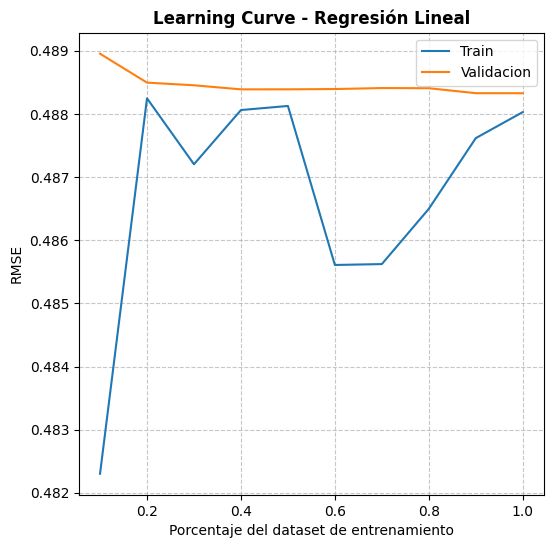

In [56]:
plot_learning_curves_linear_regression(X_train_scaled, y_train_regresion, X_val_scaled, y_val_regresion)

## Regresion Logistica con features basicas

              Train  Validation
Accuracy   0.776797    0.777062
Precision  0.307284    0.310497
Recall     0.167135    0.167416
F1         0.146760    0.147336


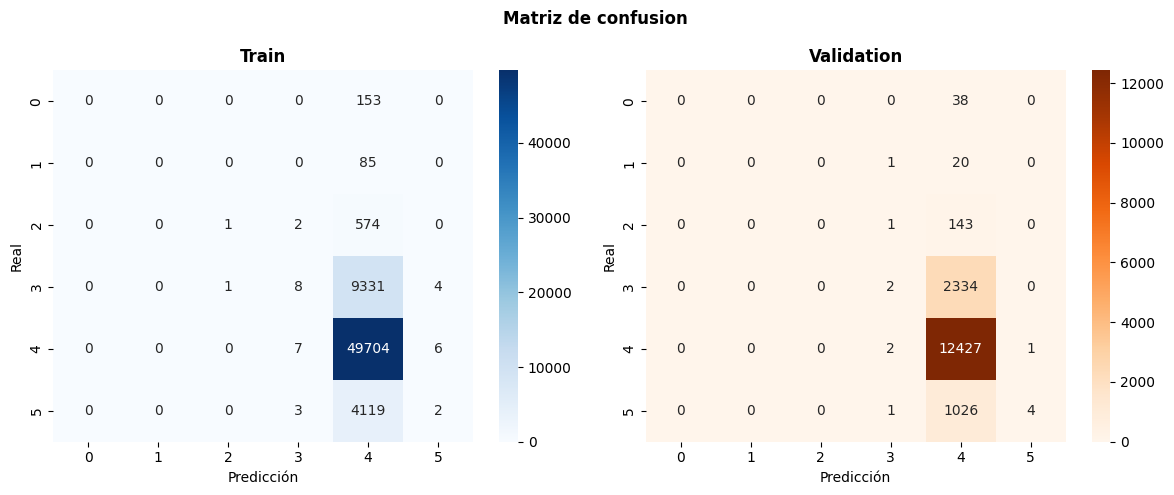

In [57]:
modeloBaseRegresionLogistica = LogisticRegression(max_iter = 1000)
modeloBaseRegresionLogistica.fit(X_train_scaled, y_train_clasificacion)

y_pred_train_modeloBaseRegresionLogistica = modeloBaseRegresionLogistica.predict(X_train_scaled)
y_pred_val_modeloBaseRegresionLogistica = modeloBaseRegresionLogistica.predict(X_val_scaled)

metricas_train_base = evaluar_metricas_clasificacion(y_pred_train_modeloBaseRegresionLogistica, y_train_clasificacion)
metricas_val_base = evaluar_metricas_clasificacion(y_pred_val_modeloBaseRegresionLogistica, y_val_clasificacion)
tabla_metricas_regresion_logistica_base = tabla_metricas(metricas_train_base, metricas_val_base, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_regresion_logistica_base)

cm_train = confusion_matrix(y_train_clasificacion, y_pred_train_modeloBaseRegresionLogistica)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_modeloBaseRegresionLogistica)
plot_confusion_matrix(cm_train, cm_val)

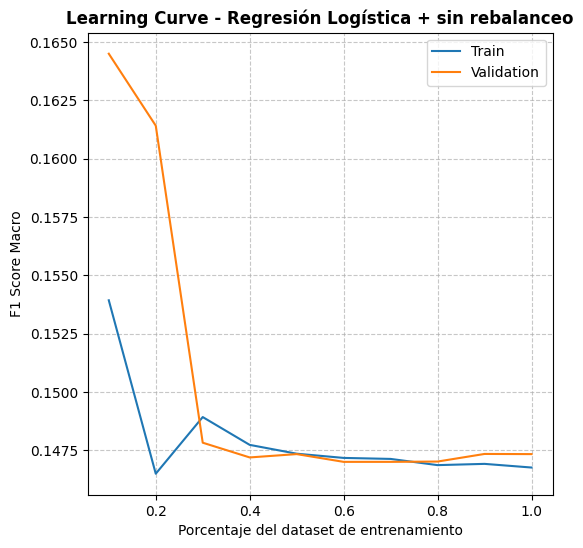

In [58]:
plot_learning_curves_logistic_regression(X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, "sin rebalanceo")

### Balanceo de clases

El primer balanceo que intento es el predeterminado de scikit learn

              Train  Validation
Accuracy   0.494266    0.485625
Precision  0.225238    0.221885
Recall     0.405405    0.375258
F1         0.211433    0.205198


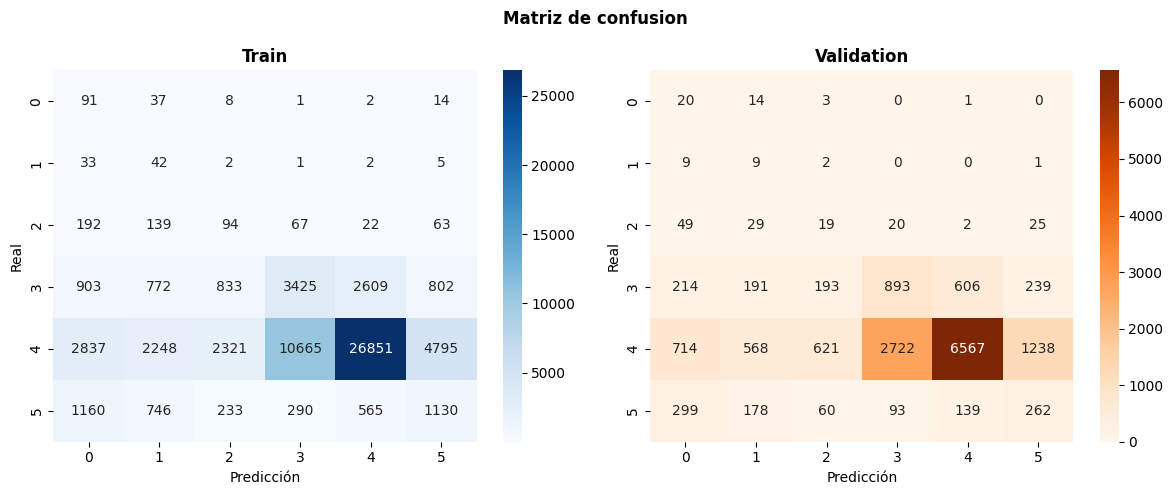

In [59]:
rebalanceo_1 = LogisticRegression(max_iter = 1000, class_weight = "balanced")
rebalanceo_1.fit(X_train_scaled, y_train_clasificacion)

y_pred_train_rebalanceo_1 = rebalanceo_1.predict(X_train_scaled)
y_pred_val_rebalanceo_1 = rebalanceo_1.predict(X_val_scaled)

metricas_train_balanced = evaluar_metricas_clasificacion(y_pred_train_rebalanceo_1, y_train_clasificacion)
metricas_val_balanced = evaluar_metricas_clasificacion(y_pred_val_rebalanceo_1, y_val_clasificacion)
tabla_metricas_regresion_logistica_1 = tabla_metricas(metricas_train_balanced, metricas_val_balanced, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_regresion_logistica_1)

cm_train = confusion_matrix(y_train_clasificacion, y_pred_train_rebalanceo_1)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_rebalanceo_1)
plot_confusion_matrix(cm_train, cm_val)

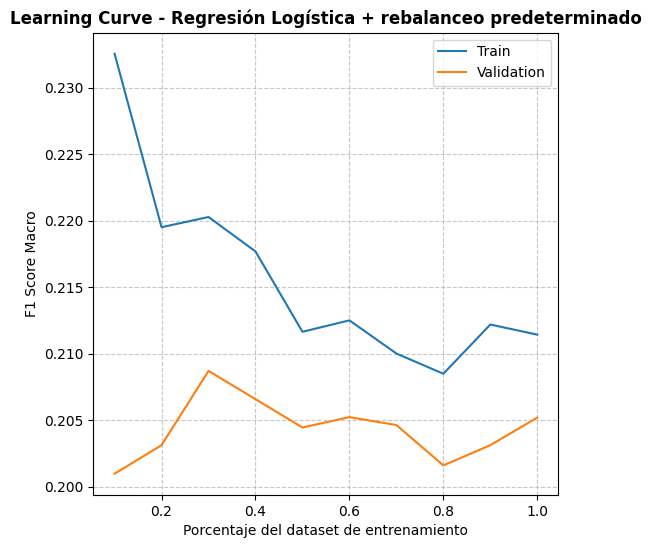

In [60]:
plot_learning_curves_logistic_regression(X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, "rebalanceo predeterminado", modelo_class_weight = "balanced")

Ahora intento ponerles pesos personalizados

              Train  Validation
Accuracy   0.756031    0.759000
Precision  0.240481    0.328285
Recall     0.225215    0.226523
F1         0.220604    0.224223


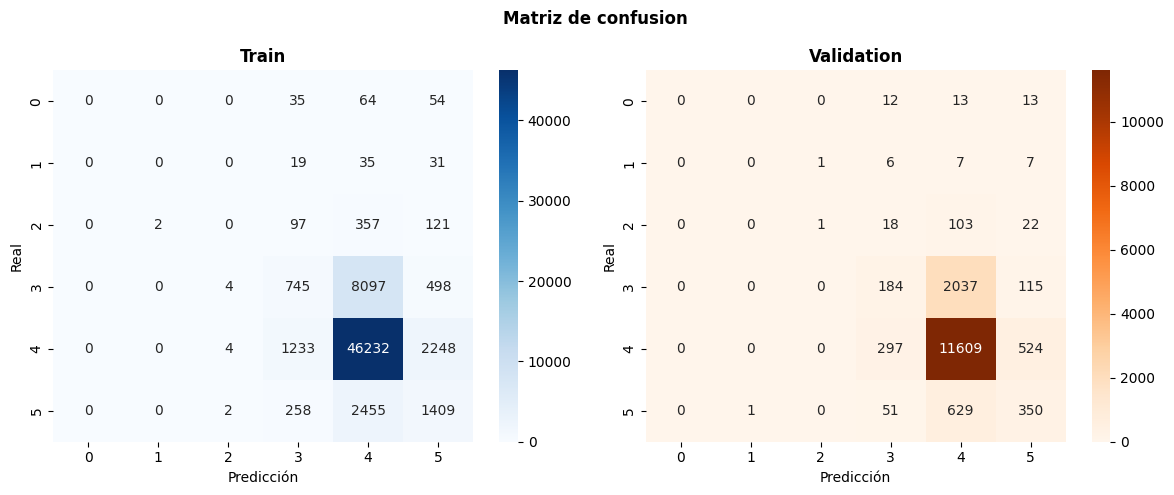

In [61]:
pesos_rlog_3 = {1:10, 2:4, 3:2, 4:1, 5:2} #defino diferentes pesos para dar prioridad a las clases mas minoritarias
rebalanceo_2 = LogisticRegression(max_iter = 1000, class_weight = pesos_rlog_3)
rebalanceo_2.fit(X_train_scaled, y_train_clasificacion)

y_pred_train_rebalanceo_2 = rebalanceo_2.predict(X_train_scaled)
y_pred_val_rebalanceo_2 = rebalanceo_2.predict(X_val_scaled)

metricas_train_manual = evaluar_metricas_clasificacion(y_pred_train_rebalanceo_2, y_train_clasificacion)
metricas_val_manual = evaluar_metricas_clasificacion(y_pred_val_rebalanceo_2, y_val_clasificacion)
tabla_metricas_regresion_logistica_2 = tabla_metricas(metricas_train_manual, metricas_val_manual, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_regresion_logistica_2)

cm_train = confusion_matrix(y_train_clasificacion, y_pred_train_rebalanceo_2)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_rebalanceo_2)
plot_confusion_matrix(cm_train, cm_val)

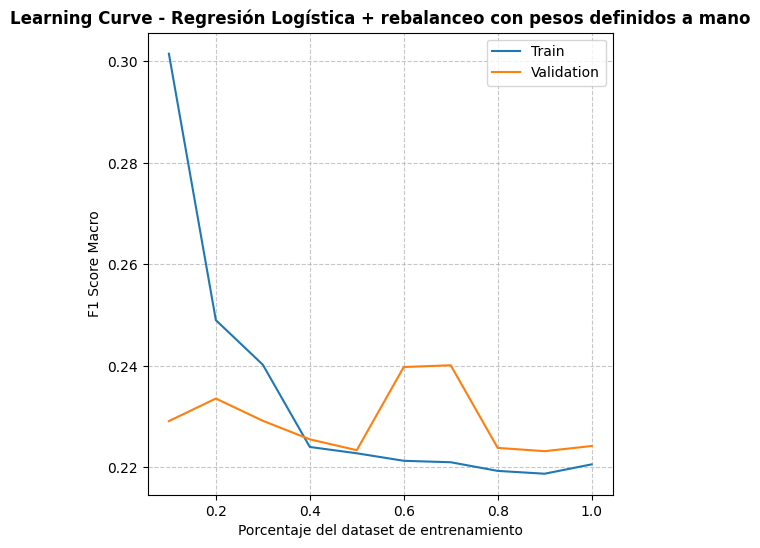

In [62]:
plot_learning_curves_logistic_regression(X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, "rebalanceo con pesos definidos a mano", modelo_class_weight = pesos_rlog_3)

              Train  Validation
Accuracy   0.684281    0.684875
Precision  0.247634    0.258842
Recall     0.274994    0.286703
F1         0.255817    0.267167


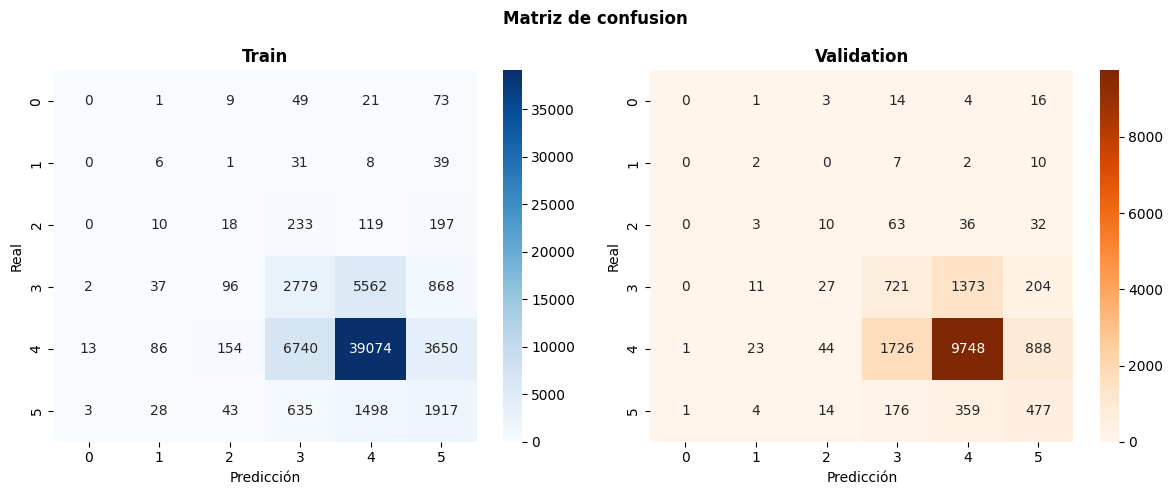

In [63]:
from imblearn.under_sampling import RandomUnderSampler

cant_datos_deseada = {4: 30000} #TODO: numero hardcodeado, adaptar al dataset q use desp
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada, random_state = 42)
X_res, y_res = undersampling.fit_resample(X_train, y_train_clasificacion) 

scaler = StandardScaler()
X_res_scaled = scaler.fit_transform(X_res)
X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)

pesos_rlog_4 = {0:12, 1:30, 2:7, 3:2, 4:1, 5:2} #TODO: ir tuneando
rebalanceo_3 = LogisticRegression(class_weight = pesos_rlog_4, max_iter = 1000)
rebalanceo_3.fit(X_res_scaled, y_res)

y_pred_train_rebalanceo_3 = rebalanceo_3.predict(X_train_scaled)
y_pred_val_rebalanceo_3 = rebalanceo_3.predict(X_val_scaled)

metricas_train_undersampling = evaluar_metricas_clasificacion(y_pred_train_rebalanceo_3, y_train_clasificacion)
metricas_val_undersampling = evaluar_metricas_clasificacion(y_pred_val_rebalanceo_3, y_val_clasificacion)
tabla_metricas_regresion_logistica_3 = tabla_metricas(metricas_train_undersampling, metricas_val_undersampling, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_regresion_logistica_3)

cm_train = confusion_matrix(y_train_clasificacion, y_pred_train_rebalanceo_3)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_rebalanceo_3)
plot_confusion_matrix(cm_train, cm_val)

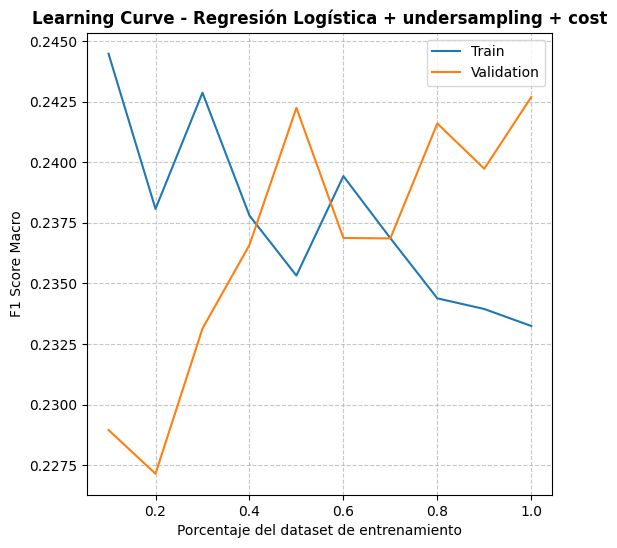

In [64]:
plot_learning_curves_logistic_regression(X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, "undersampling + cost", modelo_class_weight = pesos_rlog_4)

In [65]:
print("Comparacion de tablas de metricas segun los diferentes rebalanceos")

print("\nModelo sin rebalanceo")
print(tabla_metricas_regresion_logistica_base)

print("\nModelo con rebalanceo predeterminado")
print(tabla_metricas_regresion_logistica_1)

print("\nModelo con rebalanceo con pesos definidos a mano")
print(tabla_metricas_regresion_logistica_2)

print("\nModelo con undersampling + cost")
print(tabla_metricas_regresion_logistica_3)

Comparacion de tablas de metricas segun los diferentes rebalanceos

Modelo sin rebalanceo
              Train  Validation
Accuracy   0.776797    0.777062
Precision  0.307284    0.310497
Recall     0.167135    0.167416
F1         0.146760    0.147336

Modelo con rebalanceo predeterminado
              Train  Validation
Accuracy   0.494266    0.485625
Precision  0.225238    0.221885
Recall     0.405405    0.375258
F1         0.211433    0.205198

Modelo con rebalanceo con pesos definidos a mano
              Train  Validation
Accuracy   0.756031    0.759000
Precision  0.240481    0.328285
Recall     0.225215    0.226523
F1         0.220604    0.224223

Modelo con undersampling + cost
              Train  Validation
Accuracy   0.684281    0.684875
Precision  0.247634    0.258842
Recall     0.274994    0.286703
F1         0.255817    0.267167


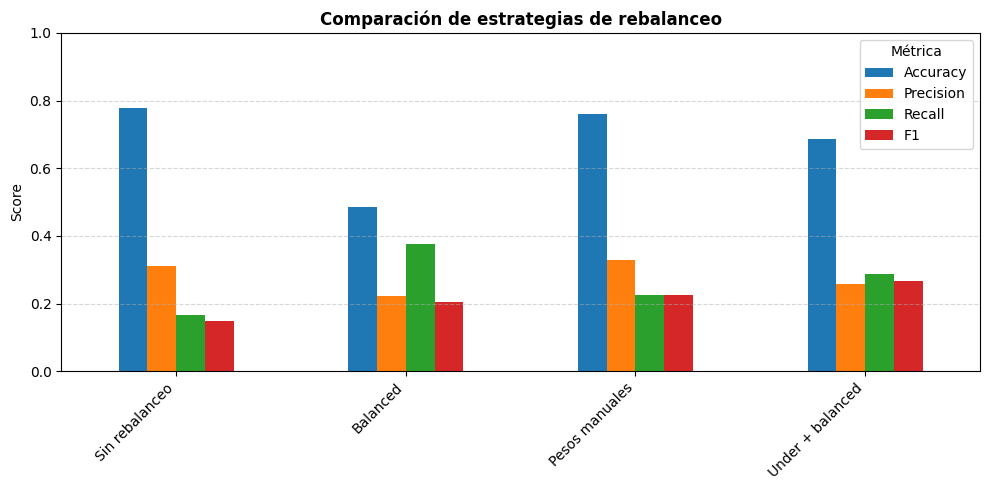

In [68]:
from src.graficos import plot_comparacion_metricas
metricas = {"Sin rebalanceo": metricas_val_base, "Balanced": metricas_val_balanced, "Pesos manuales": metricas_val_manual, "Under + balanced": metricas_val_undersampling}
plot_comparacion_metricas(metricas, "Comparación de estrategias de rebalanceo")